# AI Model Experiment & Evaluation
**Sentiment Analysis Ulasan Pelanggan: Scikit-learn vs LLM API**

Notebook ini membandingkan dua pendekatan AI pada dataset yang sama:
1. **Model klasik** — TF-IDF + Logistic Regression (Scikit-learn), dilatih sendiri.
2. **LLM API** — lewat prompting (zero-shot), tanpa training. Provider dapat dipilih: Gemini, Groq, OpenRouter, atau Ollama lokal.

> **Status notebook ini:** sudah dijalankan penuh dengan provider **Groq (`openai/gpt-oss-120b`)**; seluruh output di bawah adalah hasil run tersebut.
> Jika dijalankan ulang, prediksi LLM dibaca dari cache di `results/` (tanpa memanggil API lagi). Tanpa cache dan tanpa key, sel LLM dilewati dengan pesan jelas (bukan error).

## 1. Problem Statement

**Objective.** Tim produk e-commerce ingin fitur otomatis yang mengklasifikasikan sentimen ulasan pelanggan di halaman produk.
Eksperimen ini memberi bukti berbasis data untuk memilih pendekatan teknis sebelum masuk ke produksi.

**Target / label.** `sentiment` — klasifikasi biner: `positif` atau `negatif`.
Input model: kolom `review_text` (ulasan berbahasa Indonesia).

**Batasan & asumsi.**
- Dataset hanya 200 ulasan (110 positif, 90 negatif), tanpa label netral/campuran.
- Label pada dataset dianggap *ground truth*.
- Dataset asli di `data/` tidak diubah; semua transformasi dilakukan di memori.
- Kedua pendekatan dievaluasi pada **test set yang sama** agar adil.
- Training Deep Learning dari nol di luar cakupan (sesuai brief).
- ⚠️ Temuan penting (dibuktikan di Section 2–3): dataset hanya berisi **40 kalimat unik** yang berulang, sehingga
  split acak biasa mengalami *data leakage*. Karena itu eksperimen dijalankan dalam **dua skema evaluasi** (A dan B).

## 2. Import Library & Load Dataset

In [161]:
import os, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_recall_fscore_support)

warnings.filterwarnings('ignore')

# Library Gemini & dotenv bersifat opsional agar notebook tetap jalan tanpa error
try:
    from google import genai
    from google.genai import types
except ImportError:
    genai, types = None, None
    pass  # google-genai hanya dibutuhkan bila LLM_PROVIDER=gemini

try:
    from openai import OpenAI          # dipakai untuk Groq / OpenRouter / Ollama (API kompatibel OpenAI)
except ImportError:
    OpenAI = None

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass

# Path robust: bisa dijalankan dari folder notebook/ maupun root project
ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
DATA_PATH = ROOT / 'data' / 'customer_reviews_sentiment.csv'
RESULTS_DIR = ROOT / 'results'
DOC_DIR = ROOT / 'documentation'
RESULTS_DIR.mkdir(exist_ok=True); DOC_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
LABELS = ['negatif', 'positif']

df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
df.head()

Shape: (200, 4)


,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat diko...,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan b...",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai...",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai...",positif


In [162]:
# Eksplorasi singkat dataset
print('Distribusi label:')
print(df['sentiment'].value_counts().to_string(), '\n')
print('Missing values per kolom:'); print(df.isna().sum().to_string(), '\n')

n_unique = df['review_text'].nunique()
print(f'Jumlah baris           : {len(df)}')
print(f'Jumlah kalimat UNIK    : {n_unique}')
print(f'Rata-rata duplikasi    : {len(df)/n_unique:.1f}x per kalimat')

conflict = (df.groupby('review_text')['sentiment'].nunique() > 1).sum()
print(f'Kalimat dg label bentrok: {conflict}  (0 = label konsisten)')

Distribusi label:
sentiment
positif    110
negatif     90 

Missing values per kolom:
review_id       0
product_name    0
review_text     0
sentiment       0 

Jumlah baris           : 200
Jumlah kalimat UNIK    : 40
Rata-rata duplikasi    : 5.0x per kalimat
Kalimat dg label bentrok: 0  (0 = label konsisten)


**Interpretasi.** Hanya ada 40 kalimat unik yang diulang rata-rata 5× (dengan nama produk berbeda), dan label tiap kalimat konsisten.
Artinya dataset ini sangat bersih tetapi juga sangat repetitif — ini berdampak langsung pada cara kita harus membagi data.

## 3. Menyiapkan Train/Test Split

Pastikan test set yang sama digunakan untuk kedua pendekatan agar perbandingan adil.

Ada **dua skema** yang dipakai:

| Skema | Cara split | Tujuan |
|---|---|---|
| **A — Split standar (sesuai starter)** | `train_test_split` 80/20, stratified, `random_state=42` → 40 baris test | Memenuhi brief & starter notebook |
| **B — Leak-free (grouped)** | `StratifiedGroupKFold` 5-fold, grup = `review_text` → seluruh 200 baris diprediksi *out-of-fold*, tidak ada kalimat yang sama di train & test | Mengukur kemampuan generalisasi yang sebenarnya |

In [163]:
# ---- Skema A: split standar (sesuai starter notebook) ----
X = df['review_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print('Skema A -> Train size:', len(X_train), '| Test size:', len(X_test))
print('Distribusi test:', y_test.value_counts().to_dict())

# ---- Cek data leakage pada skema A ----
leak = X_test.isin(set(X_train)).mean()
print(f'\nPersentase baris test yang kalimatnya JUGA ada di train: {leak:.1%}')

Skema A -> Train size: 160 | Test size: 40
Distribusi test: {'positif': 22, 'negatif': 18}

Persentase baris test yang kalimatnya JUGA ada di train: 97.5%


**Interpretasi.** Hampir seluruh baris test (≈97,5%) adalah kalimat yang sudah pernah dilihat model saat training.
Skema A karenanya lebih mirip *menghafal* daripada *generalisasi* — skor tinggi di skema A **tidak** bisa dipercaya sebagai
estimasi performa di produksi (ulasan baru dari pelanggan). Skema B dibuat untuk menutup celah ini.

In [164]:
# ---- Skema B: grouped, leak-free ----
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds_B = list(sgkf.split(df['review_text'], df['sentiment'], groups=df['review_text']))

for i, (tr, te) in enumerate(folds_B, 1):
    overlap = set(df.loc[tr, 'review_text']) & set(df.loc[te, 'review_text'])
    print(f'Fold {i}: train={len(tr):3d} test={len(te):3d} | kalimat yang bocor train->test: {len(overlap)}')

Fold 1: train=160 test= 40 | kalimat yang bocor train->test: 0
Fold 2: train=159 test= 41 | kalimat yang bocor train->test: 0
Fold 3: train=161 test= 39 | kalimat yang bocor train->test: 0
Fold 4: train=160 test= 40 | kalimat yang bocor train->test: 0
Fold 5: train=160 test= 40 | kalimat yang bocor train->test: 0


## 4. Pendekatan 1 — Model Klasik (Scikit-learn)

Pipeline: **TF-IDF** (bag-of-words berbobot) → **Logistic Regression**. Dipilih karena sederhana, cepat, dan umum dipakai sebagai baseline klasifikasi teks.
Konfigurasi dibiarkan default seperti starter agar baseline mudah direproduksi.

### 4.1 Preprocessing & Feature Extraction

In [165]:
vectorizer = TfidfVectorizer()
t0 = time.perf_counter()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)
t_vec = time.perf_counter() - t0
print('Ukuran vocabulary:', len(vectorizer.vocabulary_), '| Shape X_train_vec:', X_train_vec.shape)

Ukuran vocabulary: 145 | Shape X_train_vec: (160, 145)


### 4.2 Training Model

In [166]:
clf = LogisticRegression()
t0 = time.perf_counter()
clf.fit(X_train_vec, y_train)
t_train = time.perf_counter() - t0
print(f'Waktu training: {t_train*1000:.1f} ms')

Waktu training: 9.1 ms


### 4.3 Prediksi pada Test Set

In [167]:
# Skema A
t0 = time.perf_counter()
y_pred_classic = clf.predict(X_test_vec)
t_infer = time.perf_counter() - t0
print(f'Skema A: 40 prediksi dalam {t_infer*1000:.2f} ms')

# Skema B: prediksi out-of-fold untuk seluruh 200 baris (vectorizer di-fit ulang HANYA pada train tiap fold)
y_true_B = df['sentiment'].copy()
y_pred_classic_B = pd.Series(index=df.index, dtype=object)
for tr, te in folds_B:
    v = TfidfVectorizer()
    m = LogisticRegression().fit(v.fit_transform(df.loc[tr, 'review_text']), df.loc[tr, 'sentiment'])
    y_pred_classic_B.iloc[te] = m.predict(v.transform(df.loc[te, 'review_text']))
print('Skema B: 200 prediksi out-of-fold selesai')

Skema A: 40 prediksi dalam 0.72 ms
Skema B: 200 prediksi out-of-fold selesai


In [168]:
# Kata paling berpengaruh menurut model (dilatih pada skema A) — untuk memahami apa yang dipelajari model
vocab = np.array(vectorizer.get_feature_names_out())
coef = clf.coef_[0]                      # positif => condong ke kelas clf.classes_[1] ('positif')
print('Kelas:', list(clf.classes_))
print('Top kata -> positif:', ', '.join(vocab[np.argsort(coef)[-8:][::-1]]))
print('Top kata -> negatif:', ', '.join(vocab[np.argsort(coef)[:8]]))

Kelas: ['negatif', 'positif']
Top kata -> positif: cepat, rapi, nyaman, pas, ada, lebih, puas, recommended
Top kata -> negatif: lambat, jauh, sudah, rusak, yang, tidak, sekali, seperti


## 5. Pendekatan 2 — LLM API (prompting, tanpa training)

### 5.1 Setup API

Provider dipilih lewat variabel lingkungan `LLM_PROVIDER` (file `.env`), sehingga notebook bisa berpindah provider **tanpa mengubah kode**:

| `LLM_PROVIDER` | Keterangan | Variabel yang diisi |
|---|---|---|
| `gemini` | Gemini API (sesuai brief). Free tier sering cepat habis. | `GEMINI_API_KEY` |
| `groq` | Free tier tanpa kartu kredit, sangat cepat. | `GROQ_API_KEY` |
| `openrouter` | Banyak model `:free` (batas harian ketat). | `OPENROUTER_API_KEY` |
| `ollama` | Model lokal di laptop sendiri: **tanpa key, tanpa kuota**. | — (install Ollama + `ollama pull <model>`) |
| `custom` | Endpoint kompatibel OpenAI lain. | `LLM_API_KEY`, `LLM_BASE_URL`, `LLM_MODEL` |

Model default tiap provider dapat diganti dengan `LLM_MODEL`. Katalog model gratis sering berubah — jika muncul error *model not found*, cek daftar model terbaru di dashboard provider.
> Catatan: model starter `gemini-2.0-flash` sudah **dipensiunkan Google per 1 Juni 2026**, sehingga default Gemini di sini adalah `gemini-3.6-flash`.

In [169]:
LLM_PROVIDER = os.environ.get('LLM_PROVIDER', 'groq').strip().lower()

PRESETS = {
    'gemini':     {'model': 'gemini-3.6-flash',          'key_env': 'GEMINI_API_KEY',     'base_url': None},
    'groq':       {'model': 'openai/gpt-oss-120b',       'key_env': 'GROQ_API_KEY',       'base_url': 'https://api.groq.com/openai/v1'},
    'openrouter': {'model': 'openai/gpt-oss-120b:free',  'key_env': 'OPENROUTER_API_KEY', 'base_url': 'https://openrouter.ai/api/v1'},
    'ollama':     {'model': 'llama3.2:3b',               'key_env': None,                 'base_url': 'http://localhost:11434/v1'},
    'custom':     {'model': None,                        'key_env': 'LLM_API_KEY',        'base_url': None},
}
if LLM_PROVIDER not in PRESETS:
    raise ValueError(f'LLM_PROVIDER={LLM_PROVIDER!r} tidak dikenal. Pilihan: {list(PRESETS)}')

preset = PRESETS[LLM_PROVIDER]
MODEL_NAME = os.environ.get('LLM_MODEL') or (os.environ.get('GEMINI_MODEL') if LLM_PROVIDER == 'gemini' else None) or preset['model']
BASE_URL = os.environ.get('LLM_BASE_URL') or preset['base_url']
API_KEY = os.environ.get(preset['key_env']) if preset['key_env'] else 'ollama'   # Ollama tidak butuh key (nilai bebas)

client = None
if LLM_PROVIDER == 'gemini':
    if genai is not None and API_KEY:
        client = genai.Client(api_key=API_KEY)
else:
    if OpenAI is not None and API_KEY and MODEL_NAME and BASE_URL:
        client = OpenAI(api_key=API_KEY, base_url=BASE_URL)

LLM_LABEL = f'LLM {LLM_PROVIDER}/{MODEL_NAME} (zero-shot)'
if client is not None:
    print(f'LLM client siap | provider = {LLM_PROVIDER} | model = {MODEL_NAME}')
else:
    print(f'[info] Client LLM belum siap (provider={LLM_PROVIDER}). Pastikan library terpasang & key diisi di .env:')
    print(f'       butuh {preset["key_env"] or "Ollama berjalan lokal"}; panggilan API baru akan dilewati.')
    print('       Jika file cache hasil LLM sudah ada, hasilnya tetap dipakai.')

LLM client siap | provider = groq | model = openai/gpt-oss-120b


### 5.2 Merancang Prompt

**Teknik: zero-shot.** Alasannya:
- Task biner sederhana; LLM sudah paham sentimen bahasa Indonesia tanpa contoh, dan sesuai skenario brief ("tanpa proses training").
- Zero-shot menghindari risiko *leakage*: contoh few-shot yang diambil dari dataset bisa tumpang-tindih dengan kalimat test (dataset ini sangat repetitif).
- Prompt lebih pendek → token & biaya lebih kecil.

**Elemen prompt:** peran (classifier), definisi label, format output ketat (satu kata, huruf kecil), dan satu petunjuk **negasi**
(penting di Bahasa Indonesia: "tidak kecewa" = positif). Contoh negasi sengaja *bukan* kalimat dari dataset.

**Parameter.**

| Parameter | Nilai | Alasan |
|---|---|---|
| `temperature` | `0.0` | Klasifikasi butuh output deterministik & konsisten, bukan kreativitas. |
| provider / model | `groq` / `openai/gpt-oss-120b` | Free tier tanpa kartu kredit dan cepat. Provider dipindah dari Gemini karena kuota free tier Gemini cepat habis sebelum 40 panggilan selesai. |

Catatan: sebagian model terbaru (mis. Gemini 3.x) menghapus parameter sampling seperti `temperature`. Kode di bawah mencoba `temperature=0.0`
terlebih dahulu; bila ditolak API, otomatis diulang tanpa parameter tsb dan **parameter yang benar-benar dipakai dicatat** di `LLM_STATE`.

**Hasil pencatatan parameter pada run ini:** API Groq menerima `temperature=0.0` (`use_temperature=True` pada output Section 5.3), sehingga parameter tersebut benar-benar dipakai.

In [170]:
PROMPT_TEMPLATE = '''Kamu adalah classifier sentimen untuk ulasan produk e-commerce berbahasa Indonesia.
Tentukan sentimen ulasan sebagai tepat satu label: "positif" atau "negatif".

Aturan:
- Jawab hanya dengan satu kata: positif atau negatif.
- Tanpa penjelasan, tanpa tanda baca, tanpa huruf kapital.
- Perhatikan negasi, contoh: "tidak kecewa" berarti positif, "tidak bagus" berarti negatif.

Ulasan: "{review}"
Sentimen:'''

LLM_STATE = {'provider': LLM_PROVIDER, 'model': MODEL_NAME, 'use_temperature': True, 'temperature': 0.0}
SLEEP_BETWEEN_CALLS = 2.0     # detik; naikkan jika sering kena rate limit per menit
MAX_RETRIES = 6


class QuotaExhausted(Exception):
    # Kuota HARIAN habis: retry tidak akan membantu. Simpan progres, lalu lanjutkan besok / ganti provider.
    pass


def normalize_label(raw):
    # Normalisasi output LLM -> 'positif' / 'negatif' / 'invalid'
    if raw is None:
        return 'invalid'
    tokens = re.findall(r'[a-z]+', str(raw).lower())
    for tok in tokens:
        if tok in ('positif', 'negatif'):
            return tok
    return 'invalid'


def _call_once(prompt):
    # Satu panggilan ke provider terpilih -> (teks, prompt_tokens, output_tokens, thinking_tokens)
    if LLM_PROVIDER == 'gemini':
        cfg = types.GenerateContentConfig(temperature=LLM_STATE['temperature']) if LLM_STATE['use_temperature'] else None
        resp = client.models.generate_content(model=MODEL_NAME, contents=prompt, config=cfg)
        um = getattr(resp, 'usage_metadata', None)
        return (resp.text, getattr(um, 'prompt_token_count', None),
                getattr(um, 'candidates_token_count', None), getattr(um, 'thoughts_token_count', None))
    kwargs = {'model': MODEL_NAME, 'messages': [{'role': 'user', 'content': prompt}]}
    if LLM_STATE['use_temperature']:
        kwargs['temperature'] = LLM_STATE['temperature']
    resp = client.chat.completions.create(**kwargs)
    u = getattr(resp, 'usage', None)
    details = getattr(u, 'completion_tokens_details', None)
    return (resp.choices[0].message.content, getattr(u, 'prompt_tokens', None),
            getattr(u, 'completion_tokens', None), getattr(details, 'reasoning_tokens', None))


def classify_sentiment_llm(review_text):
    # Memanggil LLM untuk satu ulasan, dengan retry/backoff. Mengembalikan dict hasil.
    prompt = PROMPT_TEMPLATE.format(review=review_text)
    last_err = None
    for attempt in range(MAX_RETRIES):
        try:
            t0 = time.perf_counter()
            text, p_tok, o_tok, th_tok = _call_once(prompt)
            return {'raw_output': (text or '').strip(), 'latency_s': round(time.perf_counter() - t0, 3),
                    'prompt_tokens': p_tok, 'output_tokens': o_tok, 'thinking_tokens': th_tok}
        except Exception as e:
            last_err = e
            msg = str(e).lower()
            flat = msg.replace(' ', '').replace('_', '')
            if LLM_STATE['use_temperature'] and 'temperature' in msg:
                LLM_STATE['use_temperature'] = False
                print('[info] API menolak parameter temperature -> diulang tanpa temperature (dicatat di LLM_STATE).')
                continue
            if any(k in flat for k in ('perday', 'daily', 'rpd', 'tpd')) and any(k in msg for k in ('429', 'quota', 'rate limit', 'exhausted')):
                raise QuotaExhausted(str(e))
            if any(k in msg for k in ('429', 'resource_exhausted', 'rate limit', '503', 'unavailable', 'overloaded', 'timeout', 'connection')):
                wait = min(60, 3 * 2 ** attempt)
                print(f'   [retry {attempt+1}/{MAX_RETRIES}] kena limit/gangguan sementara, tunggu {wait}s ...')
                time.sleep(wait)
                continue
            break
    raise RuntimeError(f'Panggilan LLM gagal: {last_err}')

print('Prompt contoh:\n')
print(PROMPT_TEMPLATE.format(review=X_test.iloc[0]))

Prompt contoh:

Kamu adalah classifier sentimen untuk ulasan produk e-commerce berbahasa Indonesia.
Tentukan sentimen ulasan sebagai tepat satu label: "positif" atau "negatif".

Aturan:
- Jawab hanya dengan satu kata: positif atau negatif.
- Tanpa penjelasan, tanpa tanda baca, tanpa huruf kapital.
- Perhatikan negasi, contoh: "tidak kecewa" berarti positif, "tidak bagus" berarti negatif.

Ulasan: "Barang tidak berfungsi sama sekali begitu diterima."
Sentimen:


### 5.3 Menjalankan Prediksi pada Test Set

**Efisiensi:** karena dataset hanya berisi 40 kalimat unik, prediksi di-*cache* per kalimat unik. Dengan `temperature=0` kalimat yang sama menghasilkan
jawaban yang sama, sehingga cukup **40 panggilan API** untuk seluruh 200 baris (mencakup test set skema A *dan* seluruh skema B).

**Tahan terhadap kuota:** cache disimpan setiap panggilan dan terpisah per provider+model (`results/llm_predictions_cache_<provider>_<model>.csv`).
Jika kuota harian habis, proses berhenti rapi; jalankan ulang sel ini besok (melanjutkan dari yang tersisa) atau ganti `LLM_PROVIDER`.

Output LLM dinormalisasi (lowercase, ambil token `positif`/`negatif`); jawaban di luar itu ditandai `invalid` dan dihitung **salah**.

In [171]:
slug = re.sub(r'[^a-zA-Z0-9]+', '_', f'{LLM_PROVIDER}_{MODEL_NAME}').strip('_').lower()
CACHE_PATH = RESULTS_DIR / f'llm_predictions_cache_{slug}.csv'
CACHE_COLS = ['review_text', 'raw_output', 'pred', 'latency_s', 'prompt_tokens', 'output_tokens', 'thinking_tokens']

cache = pd.read_csv(CACHE_PATH) if CACHE_PATH.exists() else pd.DataFrame(columns=CACHE_COLS)
unique_texts = list(df['review_text'].unique())
todo = [t for t in unique_texts if t not in set(cache['review_text'])]
print(f'Cache: {CACHE_PATH.name}')
print(f'Kalimat unik: {len(unique_texts)} | sudah di-cache: {len(unique_texts)-len(todo)} | perlu dipanggil: {len(todo)}')

if todo and client is not None:
    try:
        for i, text in enumerate(todo, 1):
            res_call = classify_sentiment_llm(text)
            res_call.update({'review_text': text, 'pred': normalize_label(res_call['raw_output'])})
            cache = pd.concat([cache, pd.DataFrame([res_call])[CACHE_COLS]], ignore_index=True)
            cache.to_csv(CACHE_PATH, index=False)           # simpan tiap panggilan
            print(f'[{i}/{len(todo)}] {res_call["pred"]:8s} ({res_call["latency_s"]}s)  {text[:60]}')
            time.sleep(SLEEP_BETWEEN_CALLS)
    except QuotaExhausted as e:
        print('\n[berhenti] Kuota harian habis. Progres tersimpan di cache.')
        print('           Jalankan ulang sel ini nanti, atau ganti LLM_PROVIDER di .env (mis. groq / ollama).')
        print('           Detail:', str(e)[:200])
elif todo:
    print('[dilewati] Client LLM belum siap dan cache belum lengkap -> isi .env (lihat 5.1) lalu jalankan ulang sel ini.')

llm_map = dict(zip(cache['review_text'], cache['pred']))
LLM_READY = all(t in llm_map for t in unique_texts)
print('\nLLM_READY =', LLM_READY, '| parameter terpakai:', LLM_STATE)

if LLM_READY:
    y_pred_llm = X_test.map(llm_map).tolist()                 # skema A (40 baris test)
    y_pred_llm_B = df['review_text'].map(llm_map)             # skema B (200 baris)
    print('Distribusi output ternormalisasi:', pd.Series(y_pred_llm_B).value_counts().to_dict())

Cache: llm_predictions_cache_groq_openai_gpt_oss_120b.csv
Kalimat unik: 40 | sudah di-cache: 0 | perlu dipanggil: 40
[1/40] negatif  (0.537s)  Pelayanan lambat dan tidak responsif saat dikomplain.
[2/40] positif  (0.703s)  Puas banget belanja disini, proses cepat dan barang aman.
[3/40] positif  (0.516s)  Terima kasih seller, barangnya awet dan sesuai deskripsi.
[4/40] negatif  (0.552s)  Warna produk berbeda jauh dari foto di listing.
[5/40] positif  (0.406s)  Packing rapi, produk sesuai deskripsi. Recommended seller!
[6/40] negatif  (1.13s)  Sudah bayar mahal tapi kualitas jauh dari ekspektasi.
[7/40] positif  (0.332s)  Belanja disini selalu puas, kualitas terjaga.
[8/40] positif  (0.379s)  Bahan nyaman dipakai, ukuran pas, tidak mengecewakan.
[9/40] negatif  (0.756s)  Barang cacat produksi, jahitan lepas di beberapa bagian.
[10/40] negatif  (0.815s)  Barang yang datang tidak sesuai dengan foto, kecewa berat.
[11/40] negatif  (0.376s)  Barang tidak berfungsi sama sekali begitu diterim

## 6. Evaluasi dan Perbandingan

Metrik dihitung **macro-average** (rata-rata sederhana kelas `negatif` dan `positif`) agar kedua kelas diperlakukan setara.

| Metrik | Arti dalam konteks ini |
|---|---|
| **Accuracy** | Proporsi ulasan yang sentimennya ditebak benar. |
| **Precision** (per kelas) | Dari semua ulasan yang ditandai kelas X, berapa yang benar-benar X. Precision `negatif` rendah → banyak ulasan bagus salah dicap negatif. |
| **Recall** (per kelas) | Dari semua ulasan yang sebenarnya X, berapa yang berhasil tertangkap. Recall `negatif` rendah → keluhan pelanggan terlewat. |
| **F1-Score** | Rata-rata harmonik precision & recall; ringkas saat keduanya perlu seimbang. |
| **Confusion matrix** | Baris = label asli, kolom = prediksi; menunjukkan jenis kesalahan (FP vs FN). |

In [172]:
def evaluate(name, y_true, y_pred, show=True):
    # Hitung metrik; prediksi 'invalid' dihitung sebagai salah.
    y_true = pd.Series(list(y_true)); y_pred = pd.Series(list(y_pred))
    acc = accuracy_score(y_true, y_pred)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, average='macro', zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    n_invalid = int((y_pred == 'invalid').sum())
    if show:
        print(f'=== {name} (n={len(y_true)}) ===')
        print(f'Accuracy: {acc:.4f}   Macro-Precision: {p:.4f}   Macro-Recall: {r:.4f}   Macro-F1: {f:.4f}')
        if n_invalid: print(f'Output invalid: {n_invalid} (dihitung salah)')
        print(classification_report(y_true, y_pred, labels=LABELS, zero_division=0))
        print('Confusion Matrix (baris=asli, kolom=prediksi; urutan negatif, positif):')
        print(cm, '\n')
    return {'Accuracy': acc, 'Precision': p, 'Recall': r, 'F1-Score': f, 'cm': cm, 'n': len(y_true), 'invalid': n_invalid}


def interpret(name, y_true, y_pred):
    # Interpretasi singkat otomatis dari angka (bukan sekadar angka).
    y_true = pd.Series(list(y_true)); y_pred = pd.Series(list(y_pred))
    acc = accuracy_score(y_true, y_pred); n = len(y_true); wrong = int(round((1-acc)*n))
    print(f'Interpretasi {name}: {n-wrong} dari {n} ulasan benar ({acc:.1%}); {wrong} salah.')
    for lab in LABELS:
        tp = int(((y_pred == lab) & (y_true == lab)).sum())
        pred_n = int((y_pred == lab).sum()); true_n = int((y_true == lab).sum())
        prec = tp / pred_n if pred_n else 0; rec = tp / true_n if true_n else 0
        print(f"  - '{lab}': precision {prec:.1%} ({tp}/{pred_n} tebakan benar), recall {rec:.1%} ({tp}/{true_n} yang asli tertangkap)")


def plot_cm(ax, cm, title):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=LABELS, yticklabels=LABELS)
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Label asli'); ax.set_title(title, fontsize=10)

### 6.1 Evaluasi Model Klasik

In [173]:
res = {}   # menampung semua hasil: res[(skema, pendekatan)] = metrik
res[('A', 'Klasik (TF-IDF + LogReg)')] = evaluate('Skema A | Model Klasik', y_test, y_pred_classic)
interpret('Skema A | Klasik', y_test, y_pred_classic)

=== Skema A | Model Klasik (n=40) ===
Accuracy: 1.0000   Macro-Precision: 1.0000   Macro-Recall: 1.0000   Macro-F1: 1.0000
              precision    recall  f1-score   support

     negatif       1.00      1.00      1.00        18
     positif       1.00      1.00      1.00        22

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40

Confusion Matrix (baris=asli, kolom=prediksi; urutan negatif, positif):
[[18  0]
 [ 0 22]] 

Interpretasi Skema A | Klasik: 40 dari 40 ulasan benar (100.0%); 0 salah.
  - 'negatif': precision 100.0% (18/18 tebakan benar), recall 100.0% (18/18 yang asli tertangkap)
  - 'positif': precision 100.0% (22/22 tebakan benar), recall 100.0% (22/22 yang asli tertangkap)


In [174]:
res[('B', 'Klasik (TF-IDF + LogReg)')] = evaluate('Skema B (leak-free) | Model Klasik', y_true_B, y_pred_classic_B)
interpret('Skema B | Klasik', y_true_B, y_pred_classic_B)

=== Skema B (leak-free) | Model Klasik (n=200) ===
Accuracy: 0.6450   Macro-Precision: 0.6407   Macro-Recall: 0.6359   Macro-F1: 0.6363
              precision    recall  f1-score   support

     negatif       0.62      0.54      0.58        90
     positif       0.66      0.73      0.69       110

    accuracy                           0.65       200
   macro avg       0.64      0.64      0.64       200
weighted avg       0.64      0.65      0.64       200

Confusion Matrix (baris=asli, kolom=prediksi; urutan negatif, positif):
[[49 41]
 [30 80]] 

Interpretasi Skema B | Klasik: 129 dari 200 ulasan benar (64.5%); 71 salah.
  - 'negatif': precision 62.0% (49/79 tebakan benar), recall 54.4% (49/90 yang asli tertangkap)
  - 'positif': precision 66.1% (80/121 tebakan benar), recall 72.7% (80/110 yang asli tertangkap)


In [175]:
# Analisis kesalahan model klasik pada skema B: kalimat mana yang paling sering salah?
err = df.assign(pred=y_pred_classic_B)
err = err[err['pred'] != err['sentiment']]
top_err = (err.groupby(['review_text', 'sentiment', 'pred']).size().reset_index(name='jumlah_salah')
              .sort_values('jumlah_salah', ascending=False))
print(f'Total salah: {len(err)} baris dari {err["review_text"].nunique()} kalimat unik\n')
print(top_err.head(10).to_string(index=False))

Total salah: 71 baris dari 13 kalimat unik

                                                 review_text sentiment    pred  jumlah_salah
       Bahan nyaman dipakai, ukuran pas, tidak mengecewakan.   positif negatif            12
     Produknya rapi dan bersih, tidak ada cacat sama sekali.   positif negatif             9
     Kualitas produk jelek, baru dipakai sekali sudah rusak.   negatif positif             8
    Produk original dan berfungsi dengan baik, terima kasih!   positif negatif             7
   Bahan murahan, tidak sesuai dengan harga yang dibayarkan.   negatif positif             6
    Sangat mengecewakan, uang saya seperti terbuang percuma.   negatif positif             6
       Pelayanan lambat dan tidak responsif saat dikomplain.   negatif positif             5
   Pengiriman berantakan, barang sampai dalam kondisi kotor.   negatif positif             4
  Pengalaman belanja terburuk, tidak akan order lagi disini.   negatif positif             4
Produk palsu, bukan barang

**Interpretasi model klasik.**
- **Skema A: sempurna (100%)** — tetapi ini *menyesatkan*: 97,5% kalimat test sudah ada di train, jadi model cukup menghafal.
- **Skema B: turun tajam (≈64,5%)** — ini estimasi yang lebih jujur untuk ulasan baru. Model sering gagal pada kalimat yang memuat **negasi atau kata ambigu**
  (mis. *"tidak mengecewakan"* = positif, *"tidak responsif"* = negatif). TF-IDF bag-of-words memperlakukan kata `tidak` secara terpisah dan tidak memahami urutan/makna,
  sementara kosakata dataset kecil (hanya 145 kata pada skema A) sehingga kata yang hanya muncul di fold test tidak dikenali.

### 6.2 Evaluasi LLM API

In [176]:
if LLM_READY:
    res[('A', LLM_LABEL)] = evaluate('Skema A | LLM', y_test, y_pred_llm)
    interpret('Skema A | LLM', y_test, y_pred_llm)
else:
    print('[dilewati] Prediksi LLM belum tersedia. Isi key di .env (lihat 5.1), jalankan ulang Section 5.3, lalu sel ini.')

=== Skema A | LLM (n=40) ===
Accuracy: 1.0000   Macro-Precision: 1.0000   Macro-Recall: 1.0000   Macro-F1: 1.0000
              precision    recall  f1-score   support

     negatif       1.00      1.00      1.00        18
     positif       1.00      1.00      1.00        22

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40

Confusion Matrix (baris=asli, kolom=prediksi; urutan negatif, positif):
[[18  0]
 [ 0 22]] 

Interpretasi Skema A | LLM: 40 dari 40 ulasan benar (100.0%); 0 salah.
  - 'negatif': precision 100.0% (18/18 tebakan benar), recall 100.0% (18/18 yang asli tertangkap)
  - 'positif': precision 100.0% (22/22 tebakan benar), recall 100.0% (22/22 yang asli tertangkap)


In [177]:
if LLM_READY:
    res[('B', LLM_LABEL)] = evaluate('Skema B (seluruh 200 baris) | LLM', y_true_B, y_pred_llm_B)
    interpret('Skema B | LLM', y_true_B, y_pred_llm_B)

    err_llm = df.assign(pred=y_pred_llm_B)
    err_llm = err_llm[err_llm['pred'] != err_llm['sentiment']]
    print(f'\nTotal salah: {len(err_llm)} baris')
    if len(err_llm):
        print(err_llm.groupby(['review_text', 'sentiment', 'pred']).size().reset_index(name='jumlah_salah')
                     .sort_values('jumlah_salah', ascending=False).head(10).to_string(index=False))
else:
    print('[dilewati] Prediksi LLM belum tersedia.')

=== Skema B (seluruh 200 baris) | LLM (n=200) ===
Accuracy: 1.0000   Macro-Precision: 1.0000   Macro-Recall: 1.0000   Macro-F1: 1.0000
              precision    recall  f1-score   support

     negatif       1.00      1.00      1.00        90
     positif       1.00      1.00      1.00       110

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200

Confusion Matrix (baris=asli, kolom=prediksi; urutan negatif, positif):
[[ 90   0]
 [  0 110]] 

Interpretasi Skema B | LLM: 200 dari 200 ulasan benar (100.0%); 0 salah.
  - 'negatif': precision 100.0% (90/90 tebakan benar), recall 100.0% (90/90 yang asli tertangkap)
  - 'positif': precision 100.0% (110/110 tebakan benar), recall 100.0% (110/110 yang asli tertangkap)

Total salah: 0 baris


**Interpretasi LLM (Groq `openai/gpt-oss-120b`, zero-shot).**
- **Skema B: 200 dari 200 benar (100%)**; precision, recall, dan F1 = 1,00 untuk kedua kelas. Confusion matrix tidak memiliki false positive maupun false negative, dan tidak ada output `invalid` (semua jawaban berhasil dinormalisasi menjadi `positif`/`negatif`).
- **Skema A dan B identik (100%)**, sesuai harapan: LLM tidak dilatih pada dataset ini sehingga tidak ada leakage — skor ini bukan hasil menghafal.
- Seluruh 13 kalimat unik yang salah diprediksi model klasik (termasuk yang bernegasi, mis. "tidak mengecewakan" dan "tidak ada cacat sama sekali") diprediksi **benar** oleh LLM. Artinya LLM menangkap makna dan negasi, bukan sekadar kata kunci.
- ⚠️ **Kehati-hatian:** 200 baris hanyalah pengulangan dari 40 kalimat unik, jadi LLM sebenarnya diuji pada 40 keputusan berbeda. Skor sempurna pada kalimat yang bersih dan polaritasnya jelas belum menjamin hasil yang sama pada ulasan nyata (sarkasme, slang, netral/campuran).

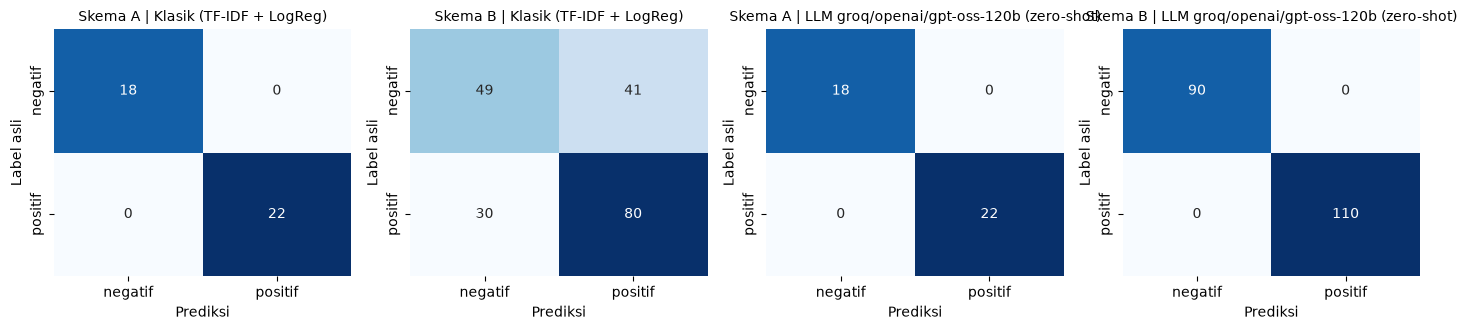

In [178]:
# Confusion matrix semua pendekatan yang sudah tersedia
keys = list(res.keys())
fig, axes = plt.subplots(1, len(keys), figsize=(3.6*len(keys), 3.4))
axes = np.atleast_1d(axes)
for ax, k in zip(axes, keys):
    plot_cm(ax, res[k]['cm'], f'Skema {k[0]} | {k[1]}')
plt.tight_layout(); plt.show()

### 6.3 Tabel Perbandingan Ringkasan

Tabel di bawah dibangun otomatis dari hasil di atas (macro-average). Skema **B** adalah acuan utama untuk keputusan karena bebas leakage.

In [180]:
rows = []
for (skema, nama), m in res.items():
    rows.append({'Skema': skema, 'Pendekatan': nama, 'n': m['n'], 'Accuracy': m['Accuracy'],
                 'Precision': m['Precision'], 'Recall': m['Recall'], 'F1-Score': m['F1-Score']})
summary = pd.DataFrame(rows).sort_values(['Skema', 'Pendekatan']).reset_index(drop=True)
summary.to_csv(RESULTS_DIR / 'model_comparison.csv', index=False)
print(summary.round(4).to_markdown(index=False))

| Skema   | Pendekatan                               |   n |   Accuracy |   Precision |   Recall |   F1-Score |
|:--------|:-----------------------------------------|----:|-----------:|------------:|---------:|-----------:|
| A       | Klasik (TF-IDF + LogReg)                 |  40 |      1     |      1      |   1      |     1      |
| A       | LLM groq/openai/gpt-oss-120b (zero-shot) |  40 |      1     |      1      |   1      |     1      |
| B       | Klasik (TF-IDF + LogReg)                 | 200 |      0.645 |      0.6407 |   0.6359 |     0.6363 |
| B       | LLM groq/openai/gpt-oss-120b (zero-shot) | 200 |      1     |      1      |   1      |     1      |


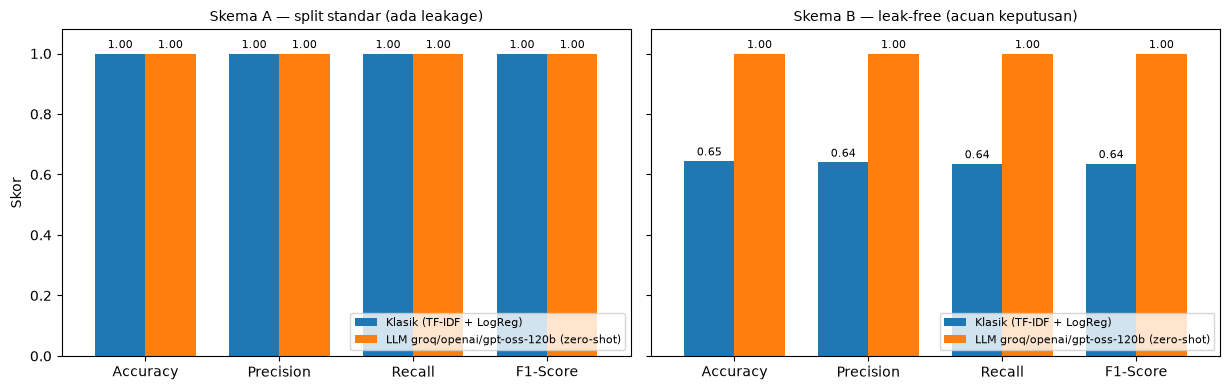

In [181]:
# Grafik ringkasan -> documentation/model_comparison_summary.png
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
schemes = sorted(summary['Skema'].unique())
fig, axes = plt.subplots(1, len(schemes), figsize=(6.2*len(schemes), 4), sharey=True)
axes = np.atleast_1d(axes)
titles = {'A': 'Skema A — split standar (ada leakage)', 'B': 'Skema B — leak-free (acuan keputusan)'}
for ax, s in zip(axes, schemes):
    sub = summary[summary['Skema'] == s].set_index('Pendekatan')[metrics]
    sub.T.plot(kind='bar', ax=ax, rot=0, width=0.75)
    ax.set_ylim(0, 1.08); ax.set_title(titles.get(s, s), fontsize=10); ax.set_xlabel('')
    for c in ax.containers: ax.bar_label(c, fmt='%.2f', fontsize=8, padding=2)
    ax.legend(fontsize=8, loc='lower right')
axes[0].set_ylabel('Skor')
plt.tight_layout()
plt.savefig(DOC_DIR / 'model_comparison_summary.png', dpi=150, bbox_inches='tight')
plt.show()

### 6.4 Perbandingan Kecepatan & Potensi Biaya

In [182]:
cost_rows = [{
    'Pendekatan': 'Klasik (TF-IDF + LogReg)',
    'Setup/training': f'{(t_vec + t_train)*1000:.0f} ms (sekali)',
    'Waktu inferensi / ulasan': f'{t_infer/len(X_test)*1000:.3f} ms',
    'Biaya per prediksi': 'Praktis 0 (CPU lokal)',
}]
if LLM_READY and cache['latency_s'].notna().any():
    lat = cache['latency_s'].astype(float).mean()
    cost_rows.append({
        'Pendekatan': LLM_LABEL,
        'Setup/training': '0 (tanpa training; cukup desain prompt)',
        'Waktu inferensi / ulasan': f'{lat*1000:.0f} ms (rata-rata, via jaringan)',
        'Biaya per prediksi': 'Berbayar per token (lihat di bawah)',
    })
print(pd.DataFrame(cost_rows).to_markdown(index=False))

# Estimasi biaya: ISI harga dari halaman pricing provider yang dipakai (USD per 1 juta token)
PRICE_INPUT_PER_1M = None
PRICE_OUTPUT_PER_1M = None
if LLM_READY and cache['prompt_tokens'].notna().any():
    tin = cache['prompt_tokens'].astype(float).mean()
    out_t = cache['output_tokens'].astype(float).fillna(0)
    think_t = cache['thinking_tokens'].astype(float).fillna(0)
    # Gemini melaporkan thinking token terpisah dari output; provider kompatibel-OpenAI (Groq dll.) sudah memasukkannya ke completion_tokens
    tout = (out_t + think_t if LLM_PROVIDER == 'gemini' else out_t).mean()
    print(f'\nRata-rata token per panggilan: input={tin:.0f}, output (termasuk reasoning)={tout:.0f}')
    if PRICE_INPUT_PER_1M is not None and PRICE_OUTPUT_PER_1M is not None:
        per_call = (tin*PRICE_INPUT_PER_1M + tout*PRICE_OUTPUT_PER_1M) / 1e6
        print(f'Estimasi biaya/prediksi: ${per_call:.6f} | per 1 juta ulasan: ${per_call*1e6:,.0f}')
    else:
        print('Isi PRICE_INPUT_PER_1M & PRICE_OUTPUT_PER_1M (USD/1 juta token) untuk menghitung estimasi biaya per 1 juta ulasan.')

| Pendekatan                               | Setup/training                          | Waktu inferensi / ulasan         | Biaya per prediksi                  |
|:-----------------------------------------|:----------------------------------------|:---------------------------------|:------------------------------------|
| Klasik (TF-IDF + LogReg)                 | 20 ms (sekali)                          | 0.018 ms                         | Praktis 0 (CPU lokal)               |
| LLM groq/openai/gpt-oss-120b (zero-shot) | 0 (tanpa training; cukup desain prompt) | 571 ms (rata-rata, via jaringan) | Berbayar per token (lihat di bawah) |

Rata-rata token per panggilan: input=185, output(+thinking)=114
Isi PRICE_INPUT_PER_1M & PRICE_OUTPUT_PER_1M (USD/1 juta token) untuk menghitung estimasi biaya per 1 juta ulasan.


**Interpretasi kecepatan & biaya.**
- **Model klasik:** setup ±20 ms (sekali), inferensi ±0,018 ms/ulasan, berjalan lokal, biaya per prediksi ≈ 0.
- **LLM:** tanpa training, tetapi ±571 ms per panggilan (rata-rata dari 40 panggilan, via jaringan) — kira-kira 30.000× lebih lambat per prediksi dan membutuhkan koneksi serta kuota API.
- **Token:** input rata-rata ±185 token per panggilan (prompt + ulasan). Output juga memakai token reasoning karena `gpt-oss-120b` adalah reasoning model, sehingga jawaban satu kata tetap memakan lebih banyak token daripada panjang jawabannya. Sel di atas sudah diperbaiki agar reasoning tidak terhitung ganda; **jalankan ulang sel 6.4 (memakai cache, tanpa panggilan API) untuk angka token output yang akurat.**
- Estimasi biaya belum dihitung karena `PRICE_INPUT_PER_1M` dan `PRICE_OUTPUT_PER_1M` masih kosong; isi dari halaman pricing Groq lalu jalankan ulang sel tersebut.

## 7. Analisis Trade-off dan Limitation

### 7.1 Performa (metrik evaluasi)

In [183]:
# Kesimpulan performa otomatis dari angka aktual (tidak ditulis manual)
def verdict(skema):
    sub = summary[summary['Skema'] == skema].set_index('Pendekatan')
    if len(sub) < 2:
        print(f'Skema {skema}: hanya satu pendekatan tersedia (LLM belum dijalankan) -> perbandingan belum bisa dibuat.')
        return
    f1 = sub['F1-Score'].round(4)
    detail = '; '.join(f'{k}: Acc {v["Accuracy"]:.3f} / F1 {v["F1-Score"]:.3f}' for k, v in sub.iterrows())
    if f1.nunique() == 1:
        print(f'Skema {skema}: SERI (F1 sama = {f1.iloc[0]:.3f}); ' + detail)
    else:
        best = f1.idxmax()
        print(f'Skema {skema}: F1 tertinggi = {best} ({sub.loc[best, "F1-Score"]:.3f}); ' + detail)

verdict('A'); verdict('B')

Skema A: SERI (F1 sama = 1.000); Klasik (TF-IDF + LogReg): Acc 1.000 / F1 1.000; LLM groq/openai/gpt-oss-120b (zero-shot): Acc 1.000 / F1 1.000
Skema B: F1 tertinggi = LLM groq/openai/gpt-oss-120b (zero-shot) (1.000); Klasik (TF-IDF + LogReg): Acc 0.645 / F1 0.636; LLM groq/openai/gpt-oss-120b (zero-shot): Acc 1.000 / F1 1.000


**Pembacaan hasil.**
- **Skema A: seri (keduanya 100%).** Angka ini tidak informatif karena 97,5% kalimat test sudah pernah dilihat model klasik saat training (leakage); LLM tidak dilatih pada dataset ini sehingga tidak terpengaruh.
- **Skema B (leak-free, acuan keputusan): LLM unggul jelas.** LLM 100% accuracy / F1 1,000 (200 dari 200 benar) vs model klasik 64,5% accuracy / F1 0,636 — selisih 35,5 poin accuracy. Model klasik salah pada 13 dari 40 kalimat unik; LLM tidak salah pada satu pun.
- Skor LLM identik di skema A dan B (100%), konsisten dengan prediksi: tanpa training, tidak ada yang bisa "bocor".
- **Catatan kehati-hatian:** 200 baris hanyalah 40 kalimat unik yang diulang, sehingga LLM sebenarnya hanya "diuji" pada 40 keputusan berbeda. Skor sempurna di dataset yang bersih dan polaritasnya jelas belum menjamin performa sempurna pada ulasan nyata.

### 7.2 Trade-off effort, kecepatan, dan biaya

| Aspek | Model klasik (Scikit-learn) | LLM API (Groq, `gpt-oss-120b`) |
|---|---|---|
| **Performa (skema B)** | Accuracy 64,5%, F1 0,636 | Accuracy 100%, F1 1,000 |
| **Effort implementasi** | Perlu data berlabel, preprocessing, training, evaluasi; kualitas bergantung pada jumlah/ragam data. | Tanpa training; cukup desain prompt & parsing output. Siap dipakai dalam hitungan menit. |
| **Kebutuhan data** | Banyak & beragam; di sini hanya 40 kalimat unik → model rapuh. | Praktis nol data berlabel (data hanya untuk evaluasi). |
| **Kecepatan** | Setup ±20 ms sekali; inferensi ±0,018 ms/ulasan (lokal). | ±571 ms/panggilan (rata-rata, via jaringan) — kira-kira 30.000× lebih lambat per prediksi; terkena rate limit. |
| **Biaya** | Sekali di muka (waktu engineer); ≈ 0 per prediksi. | Tanpa biaya training, tetapi **bayar per token pada setiap prediksi** (input rata-rata ±185 token/panggilan, ditambah output termasuk reasoning karena `gpt-oss-120b` adalah reasoning model); naik linear dengan volume. Estimasi rupiah/dolar belum dihitung karena harga belum diisi (lihat 6.4). |
| **Determinisme & kontrol** | Output deterministik, mudah di-*version*, bisa di-host sendiri. | `temperature=0` memberi output konsisten di run ini, tetapi versi model bisa berubah/dipensiunkan (mis. `gemini-2.0-flash` dimatikan 1 Juni 2026). |
| **Privasi/ketergantungan** | Data tetap di infrastruktur sendiri. | Teks ulasan dikirim ke pihak ketiga; bergantung pada ketersediaan API dan kuota. |

### 7.3 Limitation

**Model klasik (diamati)**
- *Data leakage & dataset repetitif:* skema A menghasilkan skor semu 100%; setelah leakage dihapus (skema B) turun ke 64,5%.
- *Bag-of-words tidak memahami negasi & konteks:* kesalahan terbanyak pada kalimat seperti "tidak mengecewakan" (positif, salah 12×) dan "tidak ada cacat sama sekali" (positif, salah 9×), serta pada kalimat negatif yang kata-katanya tidak dikenali (mis. "Kualitas produk jelek...", salah 8×). Lihat tabel di 6.1.
- *Out-of-vocabulary:* kata yang tidak ada di data training diabaikan sepenuhnya (vocabulary hanya 145 kata).

**LLM API**
- *Kesalahan prediksi yang diamati: tidak ada* (0 dari 200 baris, 0 output `invalid`). Karena itu keterbatasan LLM di sini bersifat **risiko, bukan temuan**: sarkasme, slang, campur bahasa, ulasan netral/campuran belum teruji.
- *Kuota & rate limit (diamati):* free tier Gemini habis sebelum eksperimen selesai sehingga provider dipindah ke Groq. Hal yang sama dapat terjadi di produksi bila kuota/limit tidak direncanakan.
- *Latensi & biaya per token:* ±571 ms per panggilan dan biaya yang naik sesuai volume; reasoning token membuat jawaban satu kata tetap memakan banyak token.
- *Perubahan model:* model bisa dipensiunkan atau berubah perilaku (Gemini 2.0 Flash dimatikan 1 Juni 2026; katalog model gratis di Groq pun berubah-ubah).
- *Provider berbeda dari brief:* brief menyebut Gemini; eksperimen dijalankan dengan Groq (`gpt-oss-120b`). Kesimpulan tentang pendekatan "LLM via prompting" berlaku umum, tetapi angka spesifik dapat berbeda pada Gemini.

**Keterbatasan eksperimen ini (kedua pendekatan)**
- Dataset kecil dan *template-like*: n efektif hanya 40 kalimat unik, sehingga interval kepercayaan lebar dan skor 100% sebaiknya tidak digeneralisasi.
- Hanya dua kelas (tidak ada `netral`); satu prompt, satu model, satu run per pendekatan (belum ada few-shot, tuning, atau perbandingan model lain).

## 8. Rekomendasi Technical Approach

**Rekomendasi: kembangkan lebih lanjut pendekatan LLM API (zero-shot prompting) untuk fitur klasifikasi sentimen ini, dengan validasi tambahan pada ulasan nyata sebelum rilis produksi.**

**Alasan (didukung hasil eksperimen):**
1. **Performa jauh lebih baik pada evaluasi yang adil.** Pada skema B (leak-free) LLM mencapai 100% accuracy/F1 vs 64,5% / 0,636 untuk model klasik. LLM benar pada seluruh kalimat yang salah diprediksi model klasik, termasuk yang bernegasi ("tidak mengecewakan", "tidak ada cacat sama sekali").
2. **Model klasik tidak generalisasi pada data ini.** Skor 100% di skema A hanyalah efek leakage; untuk ulasan baru ia hanya sedikit lebih baik dari menebak kelas mayoritas (55%).
3. **Tidak butuh data berlabel besar.** Data yang tersedia hanya 40 kalimat unik; memperbaiki model klasik memerlukan lebih banyak data beragam, sedangkan LLM bisa langsung dipakai.
4. **Time-to-market cepat dan hasil konsisten.** Tanpa training, hanya desain prompt; dengan `temperature=0` hasil konsisten pada run ini (0 output `invalid`).
5. **Biaya dan latensi dapat diterima di fase awal.** ±571 ms per panggilan cocok bila prediksi dijalankan asinkron/batch (bukan saat halaman dimuat), dan volume awal relatif kecil. Prediksi dapat di-cache per ulasan sehingga setiap ulasan hanya diproses sekali.

**Mitigasi risiko dan langkah lanjutan:**
- **Validasi lebih keras sebelum produksi:** skor 100% berasal dari 40 kalimat bersih; buat test set ulasan nyata berlabel manusia (sarkasme, slang, campur bahasa, netral/campuran) lalu ukur ulang.
- **Hitung biaya nyata:** isi harga per token di Section 6.4 lalu proyeksikan ke volume ulasan per bulan.
- Kunci versi model dan siapkan alarm deprecation; jalankan ulang evaluasi saat model diganti.
- Rencanakan kuota/rate limit (batching, retry/backoff, cache) dan fallback saat API gagal.
- Ulangi pengujian dengan Gemini (sesuai brief) bila diperlukan, untuk memastikan hasilnya setara.

**Kapan rekomendasi sebaiknya berubah:**
- Jika volume sangat besar sehingga biaya per token dominan, latensi harus sangat rendah, atau data tidak boleh keluar dari infrastruktur → latih model klasik/fine-tuned
  dengan **data yang jauh lebih besar dan beragam**; label dapat dibantu LLM lalu dikurasi manusia (pendekatan *hybrid*/distilasi).
- Jika pada test set ulasan nyata LLM ternyata jauh lebih buruk daripada di dataset ini, lakukan iterasi prompt (few-shot) sebelum memutuskan.